<a href="https://colab.research.google.com/github/Khan-Md-Shakil/Deep-Learning-A-To-Z-Practices/blob/main/Deep_Learning_and_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📚Deep Learning and Perceptron



---

## 📋 Topics Covered

1. Deep Learning vs Traditional ML
2. How Perceptron Works
3. Activation Functions
4. Batch GD vs Stochastic GD
5. Practice with Iris Dataset
6. Homework Assignment

---

## Part 1: Deep Learning vs Traditional ML

### Key Differences

| Aspect | Traditional ML | Deep Learning |
|--------|---------------|---------------|
| Features | Manual (we create them) | Automatic (model learns them) |
| Data Needed | Small datasets work | Needs large datasets |
| Training Time | Fast | Slow |
| Accuracy | Plateaus with more data | Improves with more data |

### Example: Image Recognition
- **Traditional ML:** We manually extract features (edges, colors) → Feed to classifier
- **Deep Learning:** Raw pixels → Neural network learns features automatically

> 💡 **Perceptron = Simplest neural network unit (a single neuron)**

---
## Part 2: How Perceptron Works

### Perceptron Formula
```
z = w₁×x₁ + w₂×x₂ + ... + wₙ×xₙ + b
y = activation(z)
```

**Components:**
- **x (inputs)** — Your data features
- **w (weights)** — Importance of each feature (learned by model)
- **b (bias)** — Shifts the decision boundary
- **activation** — Transforms the output (adds non-linearity)

### Why Activation Functions?
They add **non-linearity**, helping the model learn complex patterns that a straight line cannot capture.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Two most commonly used activation functions

def sigmoid(z):
    """Squashes output to range (0, 1) — used for binary classification."""
    return 1 / (1 + np.exp(-z))

def relu(z):
    """Passes positive values, zeros out negatives — widely used in deep networks."""
    return np.maximum(0, z)

print("✅ Activation functions defined!")

✅ Activation functions defined!


---
## Part 3: Batch vs Stochastic Gradient Descent

### Gradient Descent = The Learning Algorithm

**Weight update rule:**
```
w = w - learning_rate × gradient
```

### Two Main Types

| Method | Data Used Per Update | Advantages | Disadvantages |
|--------|----------------------|------------|---------------|
| **Batch GD** | All training data | Stable, smooth convergence | Slow, high memory usage |
| **Stochastic GD** | One sample at a time | Fast, can escape local minima | Noisy, less stable |

---
## Part 4: Simple Perceptron Implementation

Let's build a Perceptron **from scratch** — both Batch GD and Stochastic GD modes in one class.

In [17]:
class Perceptron:
    def __init__(self, lr=0.01, epochs=100, mode='batch'):
        """
        lr     : learning rate
        epochs : number of training passes
        mode   : 'batch' or 'stochastic'
        """
        self.lr     = lr
        self.epochs = epochs
        self.mode   = mode
        self.w      = None
        self.b      = None

    def _sigmoid(self, z):
        """Numerically stable sigmoid."""
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        n, d   = X.shape
        self.w = np.zeros(d)
        self.b = 0

        for epoch in range(self.epochs):
            if self.mode == 'batch':
                # Update using ALL samples at once
                z    = X.dot(self.w) + self.b
                pred = self._sigmoid(z)
                self.w -= self.lr * X.T.dot(pred - y) / n
                self.b -= self.lr * (pred - y).mean()
            else:
                # Update ONE sample at a time
                for i in range(n):
                    z    = X[i].dot(self.w) + self.b
                    pred = self._sigmoid(z)
                    self.w -= self.lr * (pred - y[i]) * X[i]
                    self.b -= self.lr * (pred - y[i])

    def predict(self, X):
        return (self._sigmoid(X.dot(self.w) + self.b) >= 0.5).astype(int)


print("✅ Perceptron class defined!")

✅ Perceptron class defined!


---
## Part 5: Practice with Iris Dataset

### Task: Binary Classification — Setosa vs Others

The Iris dataset has 3 flower classes (150 samples). We simplify it to a **binary problem**:  
- Class 1 → Setosa  
- Class 0 → Everything else

**Kaggle Link:** https://www.kaggle.com/datasets/uciml/iris

In [18]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

# Load dataset
iris = load_iris()
X    = iris.data
y    = (iris.target == 0).astype(int)  # 1 = Setosa, 0 = Others

print(f"Total samples: {len(X)}")
print(f"Setosa: {sum(y)}, Others: {len(y) - sum(y)}")

# Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=20
)

# Standardize features (important for gradient-based methods!)
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print("\n✅ Data ready!")

Total samples: 150
Setosa: 50, Others: 100

✅ Data ready!


In [19]:
from sklearn.metrics import precision_score, recall_score, f1_score

# ── Train with Batch Gradient Descent ──
print("=" * 50)
print("Training with BATCH Gradient Descent")
print("=" * 50)

model_batch   = Perceptron(lr=0.1, epochs=200, mode='batch')
model_batch.fit(X_train, y_train)

y_pred_batch = model_batch.predict(X_test)
acc_batch    = accuracy_score(y_test, y_pred_batch)
prec_batch   = precision_score(y_test, y_pred_batch)
rec_batch    = recall_score(y_test, y_pred_batch)
f1_batch     = f1_score(y_test, y_pred_batch)

print(f"\nTest Accuracy : {acc_batch  * 100:.2f}%")
print(f"Precision     : {prec_batch  * 100:.2f}%")
print(f"Recall        : {rec_batch   * 100:.2f}%")
print(f"F1-Score      : {f1_batch    * 100:.2f}%")
print(f"\nCorrect: {sum(y_pred_batch == y_test)}/{len(y_test)}")

Training with BATCH Gradient Descent

Test Accuracy : 100.00%
Precision     : 100.00%
Recall        : 100.00%
F1-Score      : 100.00%

Correct: 30/30


In [20]:
# ── Train with Stochastic Gradient Descent ──
print("=" * 50)
print("Training with STOCHASTIC Gradient Descent")
print("=" * 50)

model_sgd   = Perceptron(lr=0.01, epochs=200, mode='stochastic')
model_sgd.fit(X_train, y_train)

y_pred_sgd = model_sgd.predict(X_test)
acc_sgd    = accuracy_score(y_test, y_pred_sgd)
prec_sgd   = precision_score(y_test, y_pred_sgd)
rec_sgd    = recall_score(y_test, y_pred_sgd)
f1_sgd     = f1_score(y_test, y_pred_sgd)

print(f"\nTest Accuracy : {acc_sgd  * 100:.2f}%")
print(f"Precision     : {prec_sgd  * 100:.2f}%")
print(f"Recall        : {rec_sgd   * 100:.2f}%")
print(f"F1-Score      : {f1_sgd    * 100:.2f}%")
print(f"\nCorrect: {sum(y_pred_sgd == y_test)}/{len(y_test)}")

Training with STOCHASTIC Gradient Descent

Test Accuracy : 100.00%
Precision     : 100.00%
Recall        : 100.00%
F1-Score      : 100.00%

Correct: 30/30


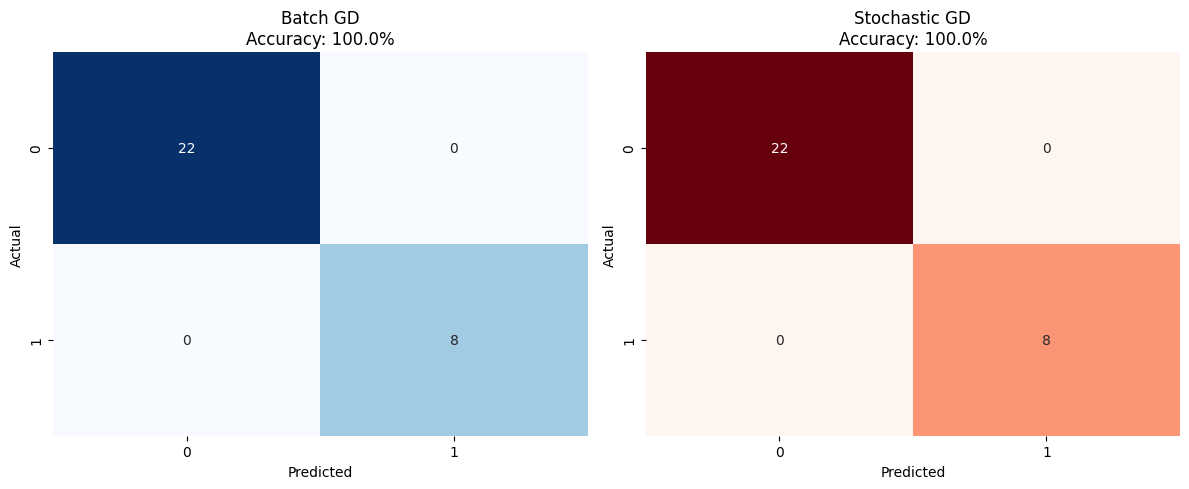


COMPARISON: Batch GD vs Stochastic GD
Metric                           Batch GD        Stochastic GD
----------------------------------------------------------------------
Accuracy                          100.00%              100.00%
Precision                         100.00%              100.00%
Recall                            100.00%              100.00%
F1-Score                          100.00%              100.00%
✅ Training complete!


In [21]:
# ── Visualize: Confusion Matrices side by side ──

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_batch = confusion_matrix(y_test, y_pred_batch)
sns.heatmap(cm_batch, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title(f'Batch GD\nAccuracy: {acc_batch * 100:.1f}%', fontsize=12)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

cm_sgd = confusion_matrix(y_test, y_pred_sgd)
sns.heatmap(cm_sgd, annot=True, fmt='d', cmap='Reds', ax=axes[1], cbar=False)
axes[1].set_title(f'Stochastic GD\nAccuracy: {acc_sgd * 100:.1f}%', fontsize=12)
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# ── Print comparison table ──
print("\n" + "=" * 70)
print("COMPARISON: Batch GD vs Stochastic GD")
print("=" * 70)
print(f"{'Metric':<20} {'Batch GD':>20} {'Stochastic GD':>20}")
print("-" * 70)
print(f"{'Accuracy':<20} {acc_batch  * 100:>19.2f}% {acc_sgd  * 100:>19.2f}%")
print(f"{'Precision':<20} {prec_batch * 100:>19.2f}% {prec_sgd * 100:>19.2f}%")
print(f"{'Recall':<20} {rec_batch  * 100:>19.2f}% {rec_sgd  * 100:>19.2f}%")
print(f"{'F1-Score':<20} {f1_batch   * 100:>19.2f}% {f1_sgd   * 100:>19.2f}%")
print("=" * 70)
print("✅ Training complete!")
print("=" * 70)

---
## Key Observations

### Batch GD
- **Stable** training — gradients are averaged over all data
- **Predictable** convergence — smooth loss curve
- **Slower** per epoch — processes all data before updating

### Stochastic GD
- **Fast** per update — one sample at a time
- Can **escape local minima** due to noisy updates
- **Noisier** convergence — zigzags toward the minimum

---

### Understanding the Metrics

> **Why not just use Accuracy?**  
> Accuracy can be misleading, especially with **imbalanced data**!

| Metric | Formula | Meaning |
|--------|---------|----------|
| **Precision** | `TP / (TP + FP)` | Of all predicted positives, how many are correct? |
| **Recall** | `TP / (TP + FN)` | Of all actual positives, how many did we catch? |
| **F1-Score** | `2 × (P × R) / (P + R)` | Harmonic mean of Precision and Recall |

---
## 📝 Homework Assignment

### Task: Credit Card Fraud Detection

**Dataset:** [Kaggle — Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)

---

### Instructions:

1. **Load and explore the dataset**
   - Check class imbalance (fraud cases are very rare — less than 0.2%!)

2. **Prepare data**
   - Handle any missing values
   - Standardize features (same as we did above)

3. **Train two models**
   - One with Batch GD
   - One with Stochastic GD

4. **Compare results:**
   - Which method converges faster?
   - Accuracy, Precision, Recall, F1-Score?

5. **Answer:** Why is Recall especially important for fraud detection?



In [22]:
# ============================================================
# HOMEWORK TEMPLATE — COMPLETE THE CODE BELOW
# ============================================================


import pandas as pd

# Step 1: Load data
# df = pd.read_csv('creditcard.csv')
# print(df.head())
# print(df['Class'].value_counts())

# Step 2: Prepare data
# X = df.drop('Class', axis=1).values
# y = df['Class'].values

# Step 3: Handle class imbalance using undersampling
# from imblearn.under_sampling import RandomUnderSampler
# rus = RandomUnderSampler(random_state=42)
# X_balanced, y_balanced = rus.fit_resample(X, y)

# Step 4: Train both models and compare results!
# Your code here...

print("Complete this code for homework!")

Complete this code for homework!


#**Part 1: Load Data & Exploratory Data Analysis (EDA)** **bold text**

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading dataset from /content/drive/MyDrive/datasets/creditcard.csv...
(Eta kichu second time nite pare)

Dataset shape: (284807, 31)
Total rows: 284,807, Total columns: 31

Class distribution (0=Normal, 1=Fraud):
Class
0    284315
1       492
Name: count, dtype: int64

Fraud cases: 0.173% (Khub kom!)


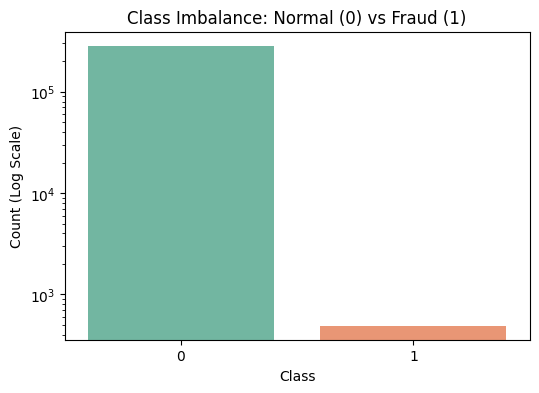


✅ Part 1 Complete: Data loaded and explored!


In [23]:
# ============================================================
# PART 1: LOAD DATA & EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from google.colab import drive
drive.mount('/content/drive')
import warnings
warnings.filterwarnings('ignore')
# file path
file_path = '/content/drive/MyDrive/datasets/creditcard.csv'

# Load dataset
print(f"Loading dataset from {file_path}...\n(Eta kichu second time nite pare)")
df = pd.read_csv(file_path)

# Dataset shape check
print(f"\nDataset shape: {df.shape}")
print(f"Total rows: {df.shape[0]:,}, Total columns: {df.shape[1]}")

# Class distribution check
print("\nClass distribution (0=Normal, 1=Fraud):")
class_counts = df['Class'].value_counts()
print(class_counts)

# Calculate fraud percentage
fraud_percentage = (class_counts[1] / class_counts.sum()) * 100
print(f"\nFraud cases: {fraud_percentage:.3f}% (Khub kom!)")

# Quick visualization of class imbalance
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df, palette='Set2')
plt.title('Class Imbalance: Normal (0) vs Fraud (1)')
plt.yscale('log') # Log scale use because huge amont of normal data
plt.ylabel('Count (Log Scale)')
plt.show()

print("\n✅ Part 1 Complete: Data loaded and explored!")

# **Part 2: Data Preparation & Handling Class Imbalance**

In [24]:
# ============================================================
# PART 2: DATA PREPARATION & HANDLING IMBALANCE
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.under_sampling import RandomUnderSampler

# Handle missing values (if any)
df = df.dropna()
print(f"Missing values handled. Current shape: {df.shape}")

# Drop the 'Time' column as it is not useful for the model
df = df.drop(['Time'], axis=1)

# Separate features and target
X = df.drop('Class', axis=1).values
y = df['Class'].values

# Standardize features (Amount column has large values, so scaling is essential)
scaler = StandardScaler()
X = scaler.fit_transform(X)
print("Features standardized successfully.")

# Apply Random Under Sampling (to balance normal and fraud classes)
print("\nApplying Random Under Sampling to handle imbalance...")
rus = RandomUnderSampler(random_state=42)
X_balanced, y_balanced = rus.fit_resample(X, y)

print("Balanced class distribution:")
print(pd.Series(y_balanced).value_counts())

# Split data into Train and Test sets (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_balanced, y_balanced, test_size=0.2, random_state=20
)

print(f"\nTraining set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")
print("\n✅ Part 2 Complete: Data ready for training!")

Missing values handled. Current shape: (284807, 31)
Features standardized successfully.

Applying Random Under Sampling to handle imbalance...
Balanced class distribution:
0    492
1    492
Name: count, dtype: int64

Training set size: 787 samples
Testing set size: 197 samples

✅ Part 2 Complete: Data ready for training!


# **Part 3: Define the Perceptron Class**

In [25]:
# ============================================================
# PART 3: PERCEPTRON CLASS (SAME AS LECTURE)
# ============================================================
class Perceptron:
    def __init__(self, lr=0.01, epochs=100, mode='batch'):
        self.lr     = lr
        self.epochs = epochs
        self.mode   = mode
        self.w      = None
        self.b      = None

    def _sigmoid(self, z):
        """Numerically stable sigmoid function."""
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        n, d   = X.shape
        self.w = np.zeros(d)
        self.b = 0

        for epoch in range(self.epochs):
            if self.mode == 'batch':
                # Update weights using ALL samples at once
                z    = X.dot(self.w) + self.b
                pred = self._sigmoid(z)
                self.w -= self.lr * X.T.dot(pred - y) / n
                self.b -= self.lr * (pred - y).mean()
            else:
                # Update weights using ONE sample at a time
                for i in range(n):
                    z    = X[i].dot(self.w) + self.b
                    pred = self._sigmoid(z)
                    self.w -= self.lr * (pred - y[i]) * X[i]
                    self.b -= self.lr * (pred - y[i])

    def predict(self, X):
        return (self._sigmoid(X.dot(self.w) + self.b) >= 0.5).astype(int)

print("✅ Part 3 Complete: Perceptron class defined!")

✅ Part 3 Complete: Perceptron class defined!


# **Part 4: Train Models & Compare Results**

In [26]:
# ============================================================
# PART 4: TRAIN MODELS & COMPARE RESULTS
# ============================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ── Train with Batch Gradient Descent ──
print("\n" + "=" * 50)
print("Training with BATCH Gradient Descent")
print("=" * 50)

start_batch = time.time()
model_batch = Perceptron(lr=0.1, epochs=100, mode='batch') # Reduced epochs to save time
model_batch.fit(X_train, y_train)
time_batch = time.time() - start_batch

y_pred_batch = model_batch.predict(X_test)
acc_batch    = accuracy_score(y_test, y_pred_batch)
prec_batch   = precision_score(y_test, y_pred_batch, zero_division=0)
rec_batch    = recall_score(y_test, y_pred_batch, zero_division=0)
f1_batch     = f1_score(y_test, y_pred_batch, zero_division=0)

print(f"Training Time : {time_batch:.4f} seconds")
print(f"Accuracy      : {acc_batch * 100:.2f}%")
print(f"Precision     : {prec_batch * 100:.2f}%")
print(f"Recall        : {rec_batch * 100:.2f}%")
print(f"F1-Score      : {f1_batch * 100:.2f}%")

# ── Train with Stochastic Gradient Descent ──
print("\n" + "=" * 50)
print("Training with STOCHASTIC Gradient Descent")
print("=" * 50)
print("(Please wait, this might take some time...)")

start_sgd = time.time()
model_sgd = Perceptron(lr=0.01, epochs=50, mode='stochastic') # Reduced epochs to save time
model_sgd.fit(X_train, y_train)
time_sgd = time.time() - start_sgd

y_pred_sgd = model_sgd.predict(X_test)
acc_sgd    = accuracy_score(y_test, y_pred_sgd)
prec_sgd   = precision_score(y_test, y_pred_sgd, zero_division=0)
rec_sgd    = recall_score(y_test, y_pred_sgd, zero_division=0)
f1_sgd     = f1_score(y_test, y_pred_sgd, zero_division=0)

print(f"Training Time : {time_sgd:.4f} seconds")
print(f"Accuracy      : {acc_sgd * 100:.2f}%")
print(f"Precision     : {prec_sgd * 100:.2f}%")
print(f"Recall        : {rec_sgd * 100:.2f}%")
print(f"F1-Score      : {f1_sgd * 100:.2f}%")

print("\n✅ Part 4 Complete: Models trained on data!")


Training with BATCH Gradient Descent
Training Time : 0.0086 seconds
Accuracy      : 92.89%
Precision     : 97.67%
Recall        : 87.50%
F1-Score      : 92.31%

Training with STOCHASTIC Gradient Descent
(Please wait, this might take some time...)
Training Time : 0.5549 seconds
Accuracy      : 93.91%
Precision     : 100.00%
Recall        : 87.50%
F1-Score      : 93.33%

✅ Part 4 Complete: Models trained on data!


# **Part 5: Visualization & Final Comparison Table**

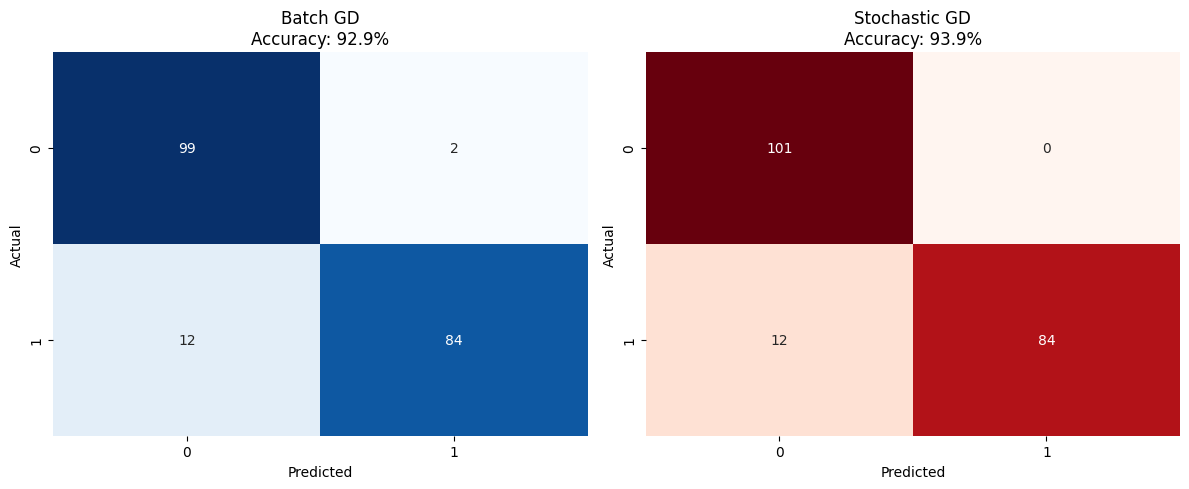


COMPARISON: Batch GD vs Stochastic GD (Fraud Data) 
Metric                           Batch GD        Stochastic GD
----------------------------------------------------------------------
Accuracy                           92.89%               93.91%
Precision                          97.67%              100.00%
Recall                             87.50%               87.50%
F1-Score                           92.31%               93.33%
Time (seconds)                    0.0086s              0.5549s
✅ Part 5 Complete: All outputs generated!


In [27]:
# ============================================================
# PART 5: VISUALIZATION & FINAL COMPARISON TABLE
# ============================================================
from sklearn.metrics import confusion_matrix

# ── Visualize: Confusion Matrices side by side ──
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_batch = confusion_matrix(y_test, y_pred_batch)
sns.heatmap(cm_batch, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title(f'Batch GD\nAccuracy: {acc_batch * 100:.1f}%', fontsize=12)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

cm_sgd = confusion_matrix(y_test, y_pred_sgd)
sns.heatmap(cm_sgd, annot=True, fmt='d', cmap='Reds', ax=axes[1], cbar=False)
axes[1].set_title(f'Stochastic GD\nAccuracy: {acc_sgd * 100:.1f}%', fontsize=12)
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# ── Print comparison table ──
print("\n" + "=" * 70)
print("COMPARISON: Batch GD vs Stochastic GD (Fraud Data) ")
print("=" * 70)
print(f"{'Metric':<20} {'Batch GD':>20} {'Stochastic GD':>20}")
print("-" * 70)
print(f"{'Accuracy':<20} {acc_batch * 100:>19.2f}% {acc_sgd * 100:>19.2f}%")
print(f"{'Precision':<20} {prec_batch * 100:>19.2f}% {prec_sgd * 100:>19.2f}%")
print(f"{'Recall':<20} {rec_batch * 100:>19.2f}% {rec_sgd * 100:>19.2f}%")
print(f"{'F1-Score':<20} {f1_batch * 100:>19.2f}% {f1_sgd * 100:>19.2f}%")
print(f"{'Time (seconds)':<20} {time_batch:>19.4f}s {time_sgd:>19.4f}s")
print("=" * 70)
print("✅ Part 5 Complete: All outputs generated!")

# **### Question: Why is Recall especially important for fraud detection?**


# **Answer:**
Recall is especially important in fraud detection because it measures how many of the actual fraud cases our model successfully caught (True Positives). If our model has low recall, it means many fraudulent transactions are being missed and classified as normal (False Negatives), which can result in huge financial losses for the bank or customers. In fraud detection, the cost of missing a fraud (False Negative) is far higher than mistakenly flagging a normal transaction as fraud (False Positive), which is why maximizing Recall is the top priority.

# **Thank You**